# Supplemental Figure 2, Panel E

Scatter plot of feature importance from random forest calculated as mean decrease in impurity vs permutation importance

*Output: PanelE.pdf*

# Setup

In [1]:
# load packages
library(tidyverse)
library(here)
here::i_am("figures/SuppFig2/PanelE/Panel_E.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank()))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig2/PanelE

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      lubridate_1.9.4 forcats_1.0.0   stringr_1.5.1  
 [5] dplyr_1.1.4     purrr_1.0.2     readr_2.1.5     tidyr_1.3.1    
 [9] tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    base64enc_0.1-3   

# Load data

In [2]:
MDI <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10uM", "feature_importance.csv"
  ),
  sep = ","
) %>%
  select(feature, MDI_importance)

PERM <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "all_cRE",
    "dose_10uM_perm", "output",
    "feature_importance.csv"
  ),
  sep = ","
) %>%
  select(feature, permutation_importance)


# Generate plot

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


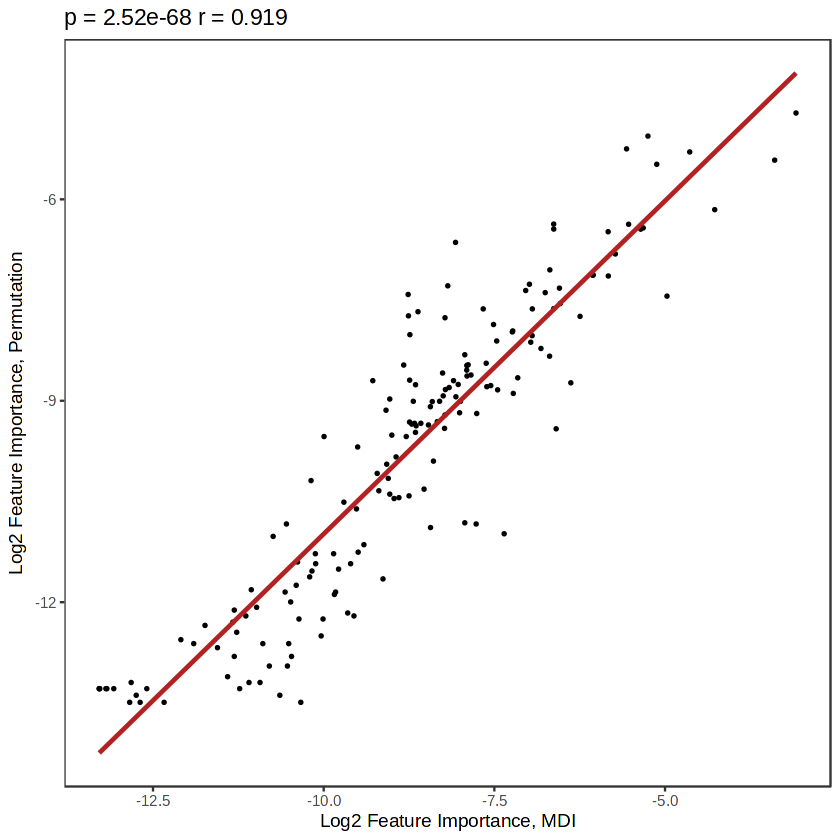

In [3]:
#get feature importance by permutation method or MDI for each feature
merge <- inner_join(MDI, PERM, by="feature")
#calculate correlation stat & p-valu
stats <- cor.test(log2(merge$MDI_importance + .0001), log2(merge$permutation_importance + .0001))

#plot
merge %>%
    ggplot(aes(x=log2(MDI_importance + .0001), y=log2(permutation_importance + .0001))) + 
    geom_point(size=.5) +
    geom_smooth(method=lm, se=F, color="firebrick") +
    xlab("Log2 Feature Importance, MDI") + ylab("Log2 Feature Importance, Permutation") +
    ggtitle(paste("p =", format(stats$p.value, digits=3), "r =", format(stats$estimate, digits=3)))
ggsave("PanelE.pdf", width=3, height=3)